In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import os

files = os.listdir('/content')

print("Uploaded files:")
for file in files:
    print(file)

Uploaded files:
.config
Copy of combined_data_1.txt.zip
sample_data


In [3]:
import zipfile

# Extract the ZIP file
zip_path = '/content/Copy of combined_data_1.txt.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/netflix_data')

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [4]:
import os

files = os.listdir('/content/netflix_data')

print("Extracted files:")
for file in files:
    print(file)

Extracted files:
combined_data_1.txt


In [5]:
file_path = '/content/netflix_data/combined_data_1.txt'

# Read first 10 lines
with open(file_path, 'r') as file:
    for i in range(10):
        print(file.readline().strip())

1:
1488844,3,2005-09-06
822109,5,2005-05-13
885013,4,2005-10-19
30878,4,2005-12-26
823519,3,2004-05-03
893988,3,2005-11-17
124105,4,2004-08-05
1248029,3,2004-04-22
1842128,4,2004-05-09


In [6]:
import pandas as pd

rows = []
current_movie_id = None

file_path = '/content/netflix_data/combined_data_1.txt'

with open(file_path, 'r') as file:

    for line in file:

        line = line.strip()

        if line.endswith(':'):
            current_movie_id = int(line[:-1])

        else:
            customer_id, rating, date = line.split(',')

            rows.append([
                current_movie_id,
                int(customer_id),
                int(rating),
                date
            ])

        if len(rows) >= 10000:
            break

# Create DataFrame
df = pd.DataFrame(
    rows,
    columns=['Movie_ID', 'Customer_ID', 'Rating', 'Date']
)

df.head()

,Movie_ID,Customer_ID,Rating,Date
0,1,1488844,3,2005-09-06
1,1,822109,5,2005-05-13
2,1,885013,4,2005-10-19
3,1,30878,4,2005-12-26
4,1,823519,3,2004-05-03


Dataset Shape: (10000, 4)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Movie_ID     10000 non-null  int64 
 1   Customer_ID  10000 non-null  int64 
 2   Rating       10000 non-null  int64 
 3   Date         10000 non-null  object
dtypes: int64(3), object(1)
memory usage: 312.6+ KB

Statistical Summary:
          Movie_ID   Customer_ID        Rating
count  10000.00000  1.000000e+04  10000.000000
mean       5.91220  1.328057e+06      3.371200
std        2.35458  7.671311e+05      1.274587
min        1.00000  6.850000e+02      1.000000
25%        3.00000  6.572415e+05      3.000000
50%        6.00000  1.335328e+06      4.000000
75%        8.00000  1.988996e+06      4.000000
max        8.00000  2.648861e+06      5.000000

Missing Values:
Movie_ID       0
Customer_ID    0
Rating         0
Date           0
dtype: int64


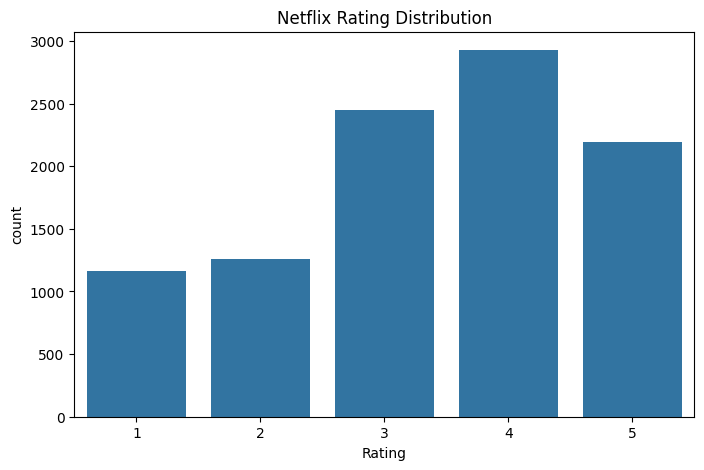

Project file saved successfully!


In [7]:
# Dataset information
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

# Rating visualization
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.countplot(x='Rating', data=df)
plt.title('Netflix Rating Distribution')
plt.show()

# Save dataset
df.to_csv('Netflix_Cleaned_Data.csv', index=False)

print("Project file saved successfully!")

Average Rating: 3.3712
Rating
1    1167
2    1263
3    2452
4    2927
5    2191
Name: count, dtype: int64


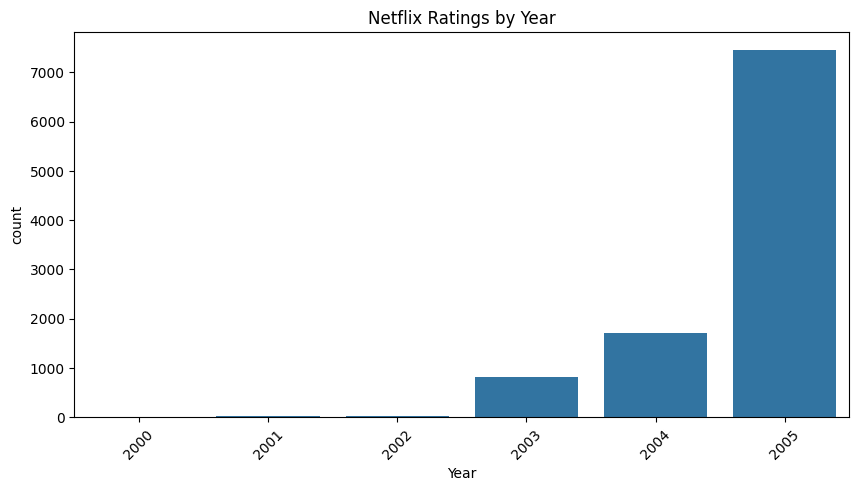

Movie_ID
1    3.749543
2    3.558621
3    3.641153
4    2.739437
5    3.919298
6    3.084396
7    2.129032
8    3.186659
Name: Rating, dtype: float64


In [8]:
# Convert Date column into datetime
df['Date'] = pd.to_datetime(df['Date'])

# 1. Average Rating
print("Average Rating:", df['Rating'].mean())

# 2. Rating Count
print(df['Rating'].value_counts().sort_index())

# 3. Ratings by Year
df['Year'] = df['Date'].dt.year

plt.figure(figsize=(10,5))
sns.countplot(x='Year', data=df)
plt.title('Netflix Ratings by Year')
plt.xticks(rotation=45)
plt.show()

# 4. Average Rating by Movie
movie_rating = df.groupby('Movie_ID')['Rating'].mean()

print(movie_rating)

In [10]:
from google.colab import files

files.download('Netflix_Cleaned_Data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

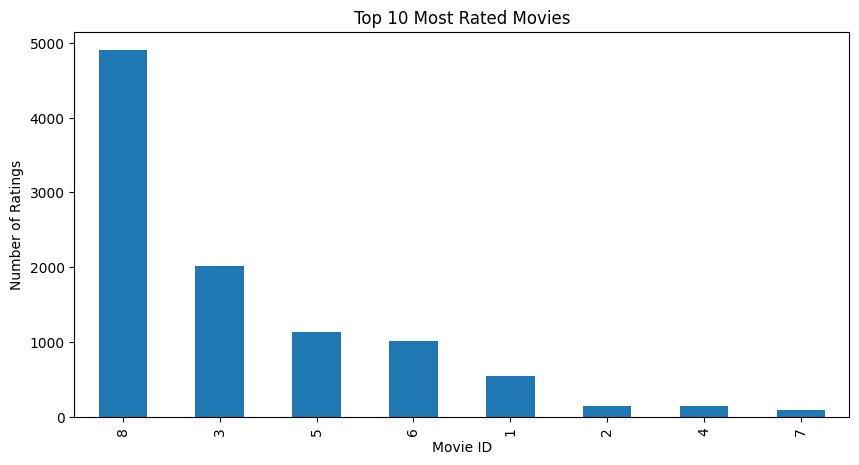

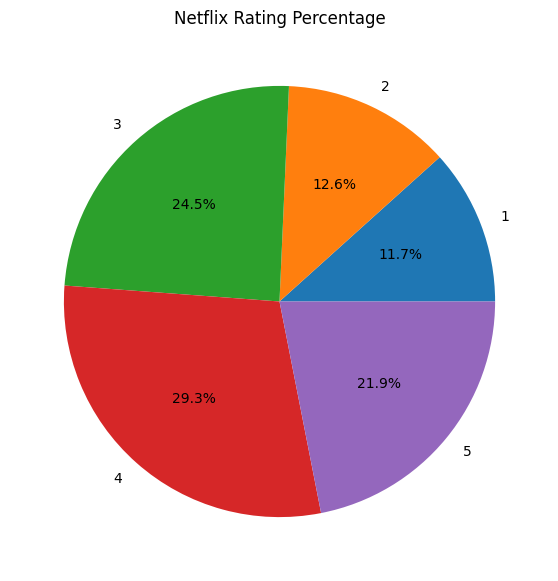

Overall Average Rating: 3.3712


In [11]:
# 1. Average rating by movie
avg_rating = df.groupby('Movie_ID')['Rating'].mean()

# 2. Top 10 most rated movies
top_movies = df['Movie_ID'].value_counts().head(10)

plt.figure(figsize=(10,5))
top_movies.plot(kind='bar')
plt.title('Top 10 Most Rated Movies')
plt.xlabel('Movie ID')
plt.ylabel('Number of Ratings')
plt.show()


# 3. Rating distribution using pie chart
df['Rating'].value_counts().sort_index().plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(7,7)
)

plt.title('Netflix Rating Percentage')
plt.ylabel('')
plt.show()


# 4. Average rating
print("Overall Average Rating:", df['Rating'].mean())